<a href="https://colab.research.google.com/github/reziepaul066-cell/WK-Mark1-Annotation/blob/main/notebooks/annotation_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# WK-Mark1 annotation pipeline (scaffold)

This notebook is the planned Google Colab entry point. It contains no inference implementation and installs no dependencies.

## Data access

The external SSD is not assumed to be directly accessible from Colab. Before a future run, configure an explicit data transfer or cloud-storage mount and set the dataset location in `configs/annotation_config.yaml`. Keep the dataset outside this Git repository.

## GitHub synchronization

In a future session, clone or pull the project repository into the Colab runtime, then import its `src` modules. Keep GPU setup and model execution in this runtime workflow. Do not commit credentials, model weights, datasets, or generated batches.

## Planned stages

1. Verify runtime and explicitly configured data access.
2. Initialize replaceable detector and segmenter adapters.
3. Process image batches and optional mask post-processing.
4. Save prediction artifacts and export them for CVAT review.

All stages above remain placeholders until implemented.

In [1]:
# Future Colab-only runtime check. No GPU work is performed by this scaffold.
# import torch
# print('CUDA available:', torch.cuda.is_available())
# if torch.cuda.is_available():
#     print('GPU:', torch.cuda.get_device_name(0))

In [2]:
# Future orchestration entry point; implementation intentionally omitted.
# from src.batch_processor import BatchProcessor
# Configure data access and adapters before enabling this workflow.

In [3]:
import sys

sys.path.insert(0, "/content/WK-Mark1-Annotation")

import src.detector
import src.segmenter
import src.mask_processor
import src.batch_processor
import src.cvat_exporter

print("All project modules imported successfully!")

All project modules imported successfully!


In [4]:
import torch
import torchvision
import cv2
import sys

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("OpenCV:", cv2.__version__)

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU Memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
OpenCV: 4.14.0

CUDA available: True
GPU: Tesla T4
GPU Memory: 14.56 GB


In [5]:
import torch
import os

print("CUDA_VISIBLE_DEVICES:", os.environ.get("CUDA_VISIBLE_DEVICES"))
print("PyTorch CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

CUDA_VISIBLE_DEVICES: None
PyTorch CUDA version: 13.0
CUDA available: True


In [6]:
%cd /content/WK-Mark1-Annotation

!ls -R

/content/WK-Mark1-Annotation
.:
configs        notebooks  README.md	    src
GroundingDINO  outputs	  requirements.txt  WK-Mark1-Annotation

./configs:
annotation_config.yaml

./GroundingDINO:
demo	    docker_test.py    groundingdino  README.md	       setup.py
Dockerfile  environment.yaml  LICENSE	     requirements.txt  test.ipynb

./GroundingDINO/demo:
create_coco_dataset.py
gradio_app.py
image_editing_with_groundingdino_gligen.ipynb
image_editing_with_groundingdino_stablediffusion.ipynb
inference_on_a_image.py
test_ap_on_coco.py

./GroundingDINO/groundingdino:
config	datasets  __init__.py  models  util

./GroundingDINO/groundingdino/config:
GroundingDINO_SwinB_cfg.py  GroundingDINO_SwinT_OGC.py	__init__.py

./GroundingDINO/groundingdino/datasets:
cocogrounding_eval.py  __init__.py  transforms.py

./GroundingDINO/groundingdino/models:
GroundingDINO  __init__.py  registry.py

./GroundingDINO/groundingdino/models/GroundingDINO:
backbone       fuse_modules.py	 ms_deform_attn.py	 utils.py


In [7]:
%cd /content

!git clone https://github.com/facebookresearch/sam2.git

%cd /content/sam2

!pip install -e .

/content
fatal: destination path 'sam2' already exists and is not an empty directory.
/content/sam2
Obtaining file:///content/sam2
  Installing build dependencies ... canceled
ERROR: Operation cancelled by user


In [8]:
import sam2

print("SAM2 imported successfully!")

SAM2 imported successfully!


In [9]:
!mkdir -p /content/sam2/checkpoints

!cd /content/sam2/checkpoints && \
wget https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt

--2026-11-27 11:50:24--  https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 65.9.168.62, 65.9.168.81, 65.9.168.52, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|65.9.168.62|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 184416285 (176M) [application/vnd.snesdev-page-table]
Saving to: ‘sam2.1_hiera_small.pt.3’

sam2.1_hiera_small. 100%[===================>] 175.87M   147MB/s    in 1.2s    

2026-11-27 11:50:26 (147 MB/s) - ‘sam2.1_hiera_small.pt.3’ saved [184416285/184416285]



In [10]:
!mkdir -p /content/sam2/checkpoints

!cd /content/sam2/checkpoints && \
wget https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt

--2026-11-27 11:50:26--  https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 65.9.168.62, 65.9.168.81, 65.9.168.52, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|65.9.168.62|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 184416285 (176M) [application/vnd.snesdev-page-table]
Saving to: ‘sam2.1_hiera_small.pt.4’

sam2.1_hiera_small. 100%[===================>] 175.87M  47.4MB/s    in 3.5s    

2026-11-27 11:50:29 (50.6 MB/s) - ‘sam2.1_hiera_small.pt.4’ saved [184416285/184416285]



In [11]:
import torch
import sam2

print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("SAM2:", "Imported successfully")

CUDA: True
GPU: Tesla T4
SAM2: Imported successfully


In [12]:
import torch
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

# Model configuration
MODEL_CFG = "configs/sam2.1/sam2.1_hiera_s.yaml"

# Checkpoint location
CHECKPOINT = "/content/sam2/checkpoints/sam2.1_hiera_small.pt"

# Load model onto GPU
sam2_model = build_sam2(
    MODEL_CFG,
    CHECKPOINT,
    device="cuda"
)

# Initialize image predictor
sam2_predictor = SAM2ImagePredictor(sam2_model)

print("SAM2 loaded successfully!")
print("Device:", next(sam2_model.parameters()).device)
print("GPU:", torch.cuda.get_device_name(0))

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


SAM2 loaded successfully!
Device: cuda:0
GPU: Tesla T4


In [14]:
!pip install -q pillow-heif

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image
from pillow_heif import register_heif_opener

# Register HEIF opener with PIL
register_heif_opener()

# Direct path to the image in the current workspace
image_path = "/content/sam2/20260819_155001.heic"

# Load the image using PIL (which now supports HEIC) and convert to RGB numpy array
dev_image = Image.open(image_path).convert("RGB")
image_rgb = np.array(dev_image)

sam2_predictor.set_image(image_rgb)

# Temporary positive point prompt
h, w = image_rgb.shape[:2]

point_coords = np.array([
    [w // 2, h // 2]
])

point_labels = np.array([1])

with torch.inference_mode(), torch.autocast(
    device_type="cuda",
    dtype=torch.float16
):
    masks, scores, logits = sam2_predictor.predict(
        point_coords=point_coords,
        point_labels=point_labels,
        multimask_output=True
    )

print("Masks generated:", masks.shape)
print("Confidence scores:", scores)

Masks generated: (3, 1848, 4000)
Confidence scores: [0.6333008  0.52441406 0.00230598]


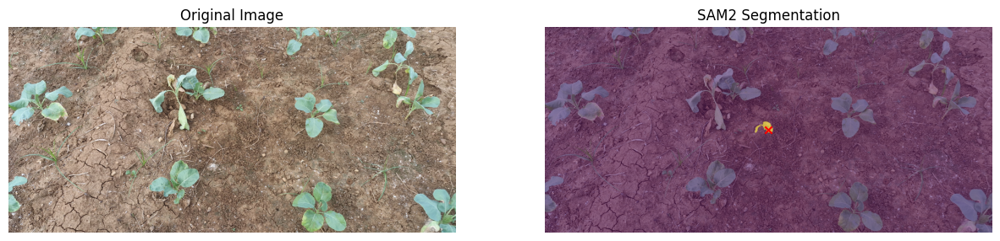

In [15]:
plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image_rgb)
plt.imshow(masks[0], alpha=0.5)
plt.scatter(
    point_coords[:, 0],
    point_coords[:, 1],
    color="red",
    marker="x"
)
plt.title("SAM2 Segmentation")
plt.axis("off")

plt.show()

In [16]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# Select a point on the central cabbage plant
point_coords = np.array([[1550, 600]])
point_labels = np.array([1])

with torch.inference_mode(), torch.autocast(
    device_type="cuda",
    dtype=torch.float16
):
    masks, scores, logits = sam2_predictor.predict(
        point_coords=point_coords,
        point_labels=point_labels,
        multimask_output=True
    )

print("Candidate scores:", scores)

Candidate scores: [0.58154297 0.40161133 0.05331421]


In [17]:
with torch.inference_mode(), torch.autocast(
    device_type="cuda",
    dtype=torch.float16
):
    masks, scores, logits = sam2_predictor.predict(
        point_coords=point_coords,
        point_labels=point_labels,
        multimask_output=True
    )

print("Candidate scores:", scores)
print("Mask dimensions:", masks.shape)

Candidate scores: [0.58154297 0.40161133 0.05331421]
Mask dimensions: (3, 1848, 4000)


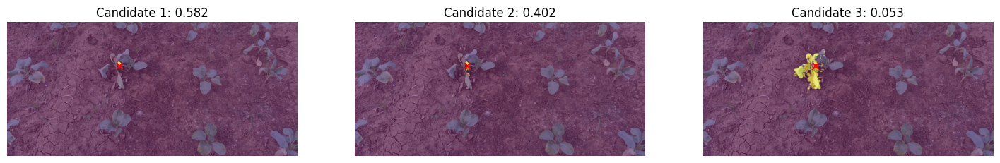

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, ax in enumerate(axes):
    ax.imshow(image_rgb)
    ax.imshow(masks[i], alpha=0.5)
    ax.scatter(1550, 600, color="red", marker="x")
    ax.set_title(f"Candidate {i+1}: {scores[i]:.3f}")
    ax.axis("off")

plt.show()

In [19]:
import numpy as np

for i in range(len(masks)):
    mask = masks[i].astype(bool)

    area = np.sum(mask)
    total = mask.size
    percentage = (area / total) * 100

    print(f"Candidate {i+1}")
    print(f"  Score: {scores[i]:.4f}")
    print(f"  Mask pixels: {area}")
    print(f"  Image coverage: {percentage:.2f}%")
    print()

Candidate 1
  Score: 0.5815
  Mask pixels: 2136
  Image coverage: 0.03%

Candidate 2
  Score: 0.4016
  Mask pixels: 4735
  Image coverage: 0.06%

Candidate 3
  Score: 0.0533
  Mask pixels: 86632
  Image coverage: 1.17%



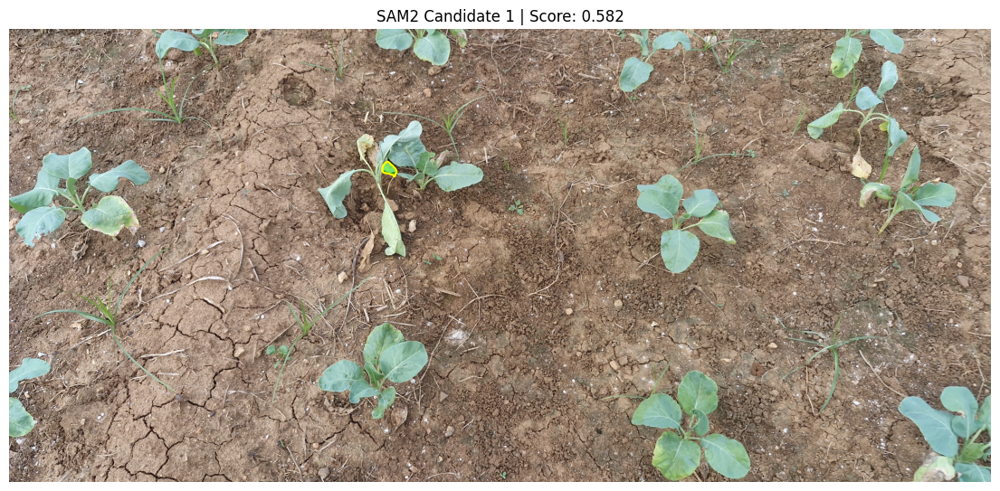

In [20]:
import matplotlib.pyplot as plt
import numpy as np

best_idx = np.argmax(scores)
best_mask = masks[best_idx].astype(bool)

plt.figure(figsize=(14, 8))
plt.imshow(image_rgb)

overlay = np.zeros((*best_mask.shape, 4))
overlay[best_mask] = [0, 1, 0, 0.45]

plt.imshow(overlay)

plt.contour(
    best_mask.astype(float),
    levels=[0.5],
    colors="yellow",
    linewidths=1.5
)

plt.title(f"SAM2 Candidate {best_idx+1} | Score: {scores[best_idx]:.3f}")
plt.axis("off")
plt.show()

In [21]:
!pip install -U transformers accelerate

In [22]:
import torch
from transformers import (
    AutoProcessor,
    AutoModelForZeroShotObjectDetection
)

MODEL_ID = "IDEA-Research/grounding-dino-tiny"

processor = AutoProcessor.from_pretrained(MODEL_ID)

grounding_model = AutoModelForZeroShotObjectDetection.from_pretrained(
    MODEL_ID
).to("cuda")

grounding_model.eval()

print("Grounding DINO loaded!")
print("GPU:", torch.cuda.get_device_name(0))

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

Grounding DINO loaded!
GPU: Tesla T4


In [23]:
TEXT_PROMPT = (
    "cabbage plant. "
    "grass weed."
)

inputs = processor(
    images=image_rgb,
    text=TEXT_PROMPT,
    return_tensors="pt"
).to("cuda")

with torch.inference_mode():
    outputs = grounding_model(**inputs)

results = processor.post_process_grounded_object_detection(
    outputs,
    inputs.input_ids,
    threshold=0.25,
    text_threshold=0.20,
    target_sizes=[image_rgb.shape[:2]]
)[0]

print("Detected objects:", len(results["boxes"]))

for box, score, label in zip(
    results["boxes"],
    results["scores"],
    results["text_labels"]
):
    print(
        f"Class: {label} | "
        f"Confidence: {score.item():.3f} | "
        f"Box: {box.tolist()}"
    )

Detected objects: 10
Class: cabbage plant grass weed | Confidence: 0.393 | Box: [3236.6396484375, 3.1396703720092773, 3861.8046875, 847.252197265625]
Class: cabbage plant grass weed | Confidence: 0.370 | Box: [2422.12158203125, 1359.9114990234375, 3024.916748046875, 1839.2703857421875]
Class: cabbage plant grass weed | Confidence: 0.406 | Box: [2551.509765625, 591.2832641601562, 2962.68994140625, 1002.5437622070312]
Class: cabbage plant grass weed | Confidence: 0.379 | Box: [1253.2564697265625, 1193.0660400390625, 1710.1329345703125, 1594.4967041015625]
Class: cabbage plant grass weed | Confidence: 0.343 | Box: [3619.595947265625, 1450.176513671875, 3994.964111328125, 1842.2264404296875]
Class: cabbage plant grass weed | Confidence: 0.295 | Box: [1252.70068359375, 275.8487243652344, 1943.6243896484375, 937.2015380859375]
Class: cabbage plant grass weed | Confidence: 0.358 | Box: [4.616737365722656, 476.5320739746094, 574.1823120117188, 899.3140258789062]
Class: grass weed | Confidence:

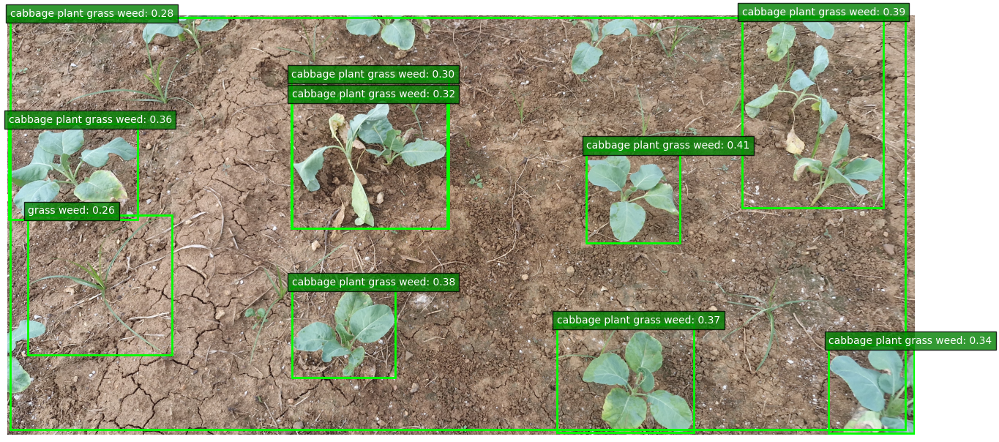

In [24]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(16, 9))
ax.imshow(image_rgb)

for box, score, label in zip(
    results["boxes"],
    results["scores"],
    results["text_labels"]
):
    x1, y1, x2, y2 = box.cpu().numpy()

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=2,
        edgecolor="lime",
        facecolor="none"
    )

    ax.add_patch(rect)

    ax.text(
        x1,
        y1 - 5,
        f"{label}: {score:.2f}",
        color="white",
        bbox=dict(facecolor="green", alpha=0.8)
    )

ax.axis("off")
plt.show()


In [25]:
def detect_objects(image, prompt, threshold=0.30):

    inputs = processor(
        images=image,
        text=prompt,
        return_tensors="pt"
    ).to("cuda")

    with torch.inference_mode():
        outputs = grounding_model(**inputs)

    results = processor.post_process_grounded_object_detection(
        outputs,
        inputs.input_ids,
        threshold=threshold,
        text_threshold=0.25,
        target_sizes=[image.shape[:2]]
    )[0]

    return results

In [26]:
crop_results = detect_objects(
    image_rgb,
    "cabbage plant.",
    threshold=0.30
)

print("Crop detections:", len(crop_results["boxes"]))

for box, score in zip(
    crop_results["boxes"],
    crop_results["scores"]
):
    print(f"Confidence: {score.item():.3f}")

Crop detections: 8
Confidence: 0.597
Confidence: 0.582
Confidence: 0.509
Confidence: 0.517
Confidence: 0.541
Confidence: 0.469
Confidence: 0.382
Confidence: 0.349


In [27]:
weed_results = detect_objects(
    image_rgb,
    "grass weed.",
    threshold=0.25
)

print("Weed detections:", len(weed_results["boxes"]))

for box, score in zip(
    weed_results["boxes"],
    weed_results["scores"]
):
    print(f"Confidence: {score.item():.3f}")

Weed detections: 17
Confidence: 0.515
Confidence: 0.542
Confidence: 0.509
Confidence: 0.524
Confidence: 0.380
Confidence: 0.496
Confidence: 0.489
Confidence: 0.368
Confidence: 0.322
Confidence: 0.397
Confidence: 0.309
Confidence: 0.339
Confidence: 0.311
Confidence: 0.282
Confidence: 0.282
Confidence: 0.314
Confidence: 0.265


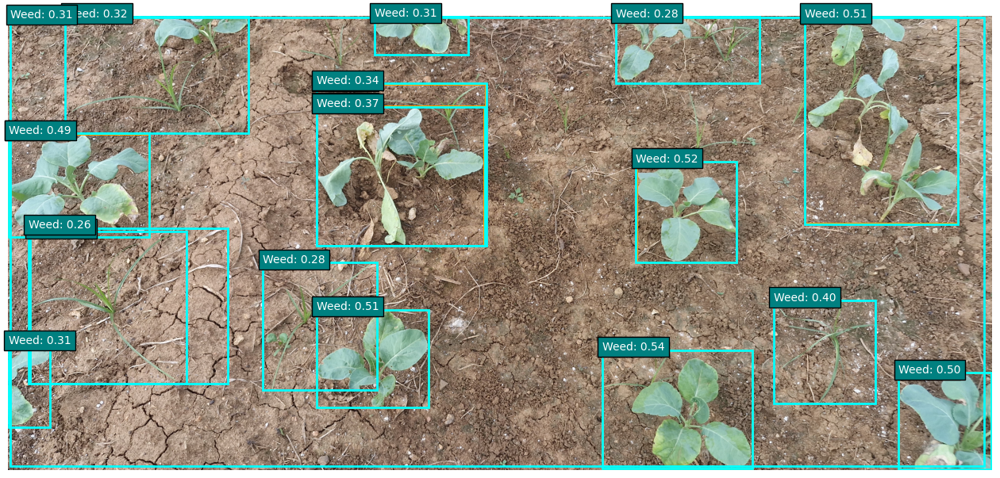

In [28]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(16, 9))

ax.imshow(image_rgb)

# Crop detections
for box, score in zip(
    crop_results["boxes"],
    crop_results["scores"]
):
    x1, y1, x2, y2 = box.cpu().numpy()

    rect = patches.Rectangle(
        (x1, y1),
        x2-x1,
        y2-y1,
        linewidth=2,
        edgecolor="orange",
        facecolor="none"
    )

    ax.add_patch(rect)

    ax.text(
        x1, y1,
        f"Crop: {score:.2f}",
        color="white",
        bbox=dict(facecolor="orange")
    )

# Weed detections
for box, score in zip(
    weed_results["boxes"],
    weed_results["scores"]
):
    x1, y1, x2, y2 = box.cpu().numpy()

    rect = patches.Rectangle(
        (x1, y1),
        x2-x1,
        y2-y1,
        linewidth=2,
        edgecolor="cyan",
        facecolor="none"
    )

    ax.add_patch(rect)

    ax.text(
        x1, y1,
        f"Weed: {score:.2f}",
        color="white",
        bbox=dict(facecolor="teal")
    )

ax.axis("off")
plt.show()

In [29]:
print("========== CROP DETECTIONS ==========")

print("Count:", len(crop_results["boxes"]))

for box, score in zip(
    crop_results["boxes"],
    crop_results["scores"]
):
    print(f"Confidence: {score.item():.3f}")


print("\n========== WEED DETECTIONS ==========")

print("Count:", len(weed_results["boxes"]))

for box, score in zip(
    weed_results["boxes"],
    weed_results["scores"]
):
    print(f"Confidence: {score.item():.3f}")

========== CROP DETECTIONS ==========
Count: 8
Confidence: 0.597
Confidence: 0.582
Confidence: 0.509
Confidence: 0.517
Confidence: 0.541
Confidence: 0.469
Confidence: 0.382
Confidence: 0.349

========== WEED DETECTIONS ==========
Count: 17
Confidence: 0.515
Confidence: 0.542
Confidence: 0.509
Confidence: 0.524
Confidence: 0.380
Confidence: 0.496
Confidence: 0.489
Confidence: 0.368
Confidence: 0.322
Confidence: 0.397
Confidence: 0.309
Confidence: 0.339
Confidence: 0.311
Confidence: 0.282
Confidence: 0.282
Confidence: 0.314
Confidence: 0.265


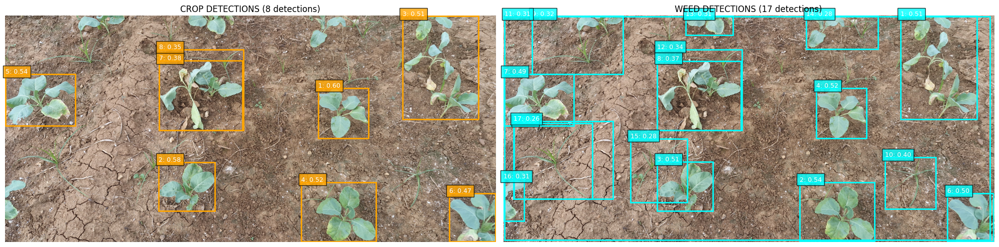

In [30]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, axes = plt.subplots(1, 2, figsize=(20, 9))

detection_sets = [
    (crop_results, "CROP DETECTIONS", "orange"),
    (weed_results, "WEED DETECTIONS", "cyan")
]

for ax, (results, title, color) in zip(axes, detection_sets):

    ax.imshow(image_rgb)

    for i, (box, score) in enumerate(zip(
        results["boxes"],
        results["scores"]
    )):

        x1, y1, x2, y2 = box.cpu().numpy()

        rect = patches.Rectangle(
            (x1, y1),
            x2-x1,
            y2-y1,
            linewidth=2,
            edgecolor=color,
            facecolor="none"
        )

        ax.add_patch(rect)

        ax.text(
            x1,
            max(0, y1-8),
            f"{i+1}: {score.item():.2f}",
            color="white",
            fontsize=9,
            bbox=dict(facecolor=color, alpha=0.8)
        )

    ax.set_title(f"{title} ({len(results['boxes'])} detections)")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [31]:
prompts = {
    "Crop 1": "young cabbage seedling.",
    "Crop 2": "cabbage plant with green leaves.",
    "Crop 3": "individual cabbage crop.",
    "Weed 1": "grass growing in agricultural soil.",
    "Weed 2": "thin grass-like weed.",
    "Weed 3": "unwanted grassy plant among crops."
}

prompt_results = {}

for name, prompt in prompts.items():

    result = detect_objects(
        image_rgb,
        prompt,
        threshold=0.25
    )

    prompt_results[name] = result

    print(f"\n{name}: {prompt}")
    print("Detections:", len(result["boxes"]))

    for score in result["scores"]:
        print(f"  Confidence: {score.item():.3f}")


Crop 1: young cabbage seedling.
Detections: 4
  Confidence: 0.464
  Confidence: 0.383
  Confidence: 0.340
  Confidence: 0.290

Crop 2: cabbage plant with green leaves.
Detections: 11
  Confidence: 0.459
  Confidence: 0.298
  Confidence: 0.473
  Confidence: 0.473
  Confidence: 0.313
  Confidence: 0.368
  Confidence: 0.314
  Confidence: 0.451
  Confidence: 0.271
  Confidence: 0.360
  Confidence: 0.297

Crop 3: individual cabbage crop.
Detections: 9
  Confidence: 0.373
  Confidence: 0.408
  Confidence: 0.278
  Confidence: 0.322
  Confidence: 0.364
  Confidence: 0.256
  Confidence: 0.251
  Confidence: 0.258
  Confidence: 0.310

Weed 1: grass growing in agricultural soil.
Detections: 8
  Confidence: 0.398
  Confidence: 0.602
  Confidence: 0.295
  Confidence: 0.302
  Confidence: 0.269
  Confidence: 0.272
  Confidence: 0.293
  Confidence: 0.273

Weed 2: thin grass-like weed.
Detections: 8
  Confidence: 0.291
  Confidence: 0.382
  Confidence: 0.348
  Confidence: 0.318
  Confidence: 0.353
  Co

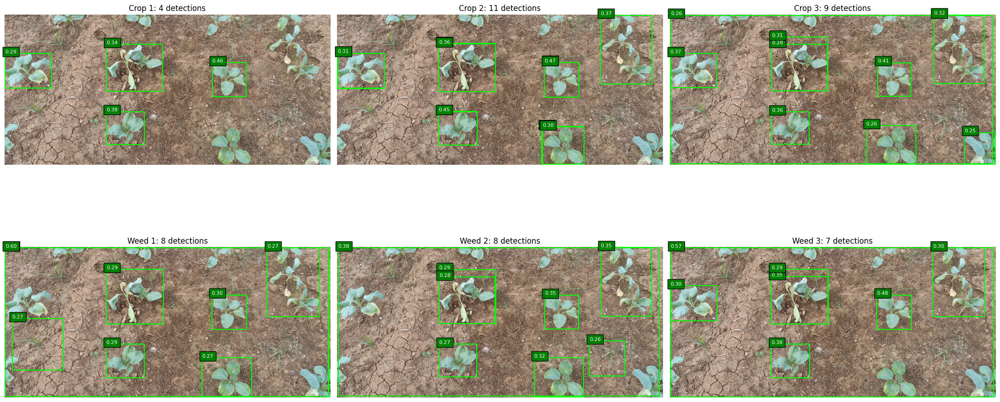

In [32]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, axes = plt.subplots(2, 3, figsize=(22, 12))

for ax, (name, result) in zip(
    axes.flatten(),
    prompt_results.items()
):

    ax.imshow(image_rgb)

    for box, score in zip(
        result["boxes"],
        result["scores"]
    ):

        x1, y1, x2, y2 = box.cpu().numpy()

        rect = patches.Rectangle(
            (x1, y1),
            x2-x1,
            y2-y1,
            linewidth=1.5,
            edgecolor="lime",
            facecolor="none"
        )

        ax.add_patch(rect)

        ax.text(
            x1,
            max(0, y1-5),
            f"{score.item():.2f}",
            color="white",
            fontsize=8,
            bbox=dict(facecolor="green")
        )

    ax.set_title(
        f"{name}: {len(result['boxes'])} detections"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [33]:
import torch
from torchvision.ops import nms

boxes = crop_results["boxes"]
scores = crop_results["scores"]

keep = nms(
    boxes,
    scores,
    iou_threshold=0.5
)

filtered_boxes = boxes[keep]
filtered_scores = scores[keep]

print("Original detections:", len(boxes))
print("After NMS:", len(filtered_boxes))

Original detections: 8
After NMS: 7


In [34]:
import numpy as np

sam2_predictor.set_image(image_rgb)

plant_masks = []
plant_scores = []

for box in filtered_boxes:

    box_np = box.cpu().numpy()

    with torch.inference_mode(), torch.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):

        masks, scores, logits = sam2_predictor.predict(
            box=box_np,
            multimask_output=True
        )

    best_idx = np.argmax(scores)

    plant_masks.append(masks[best_idx])
    plant_scores.append(scores[best_idx])

print("Generated masks:", len(plant_masks))

Generated masks: 7


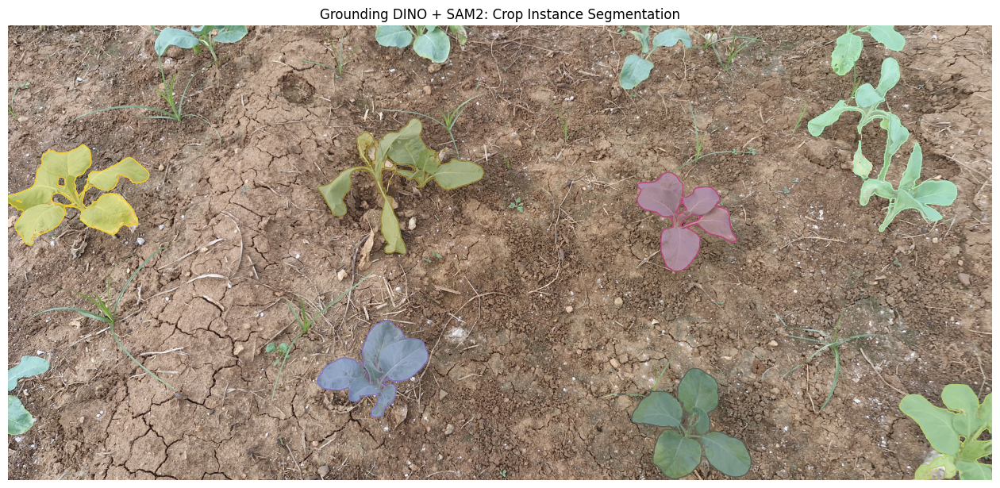

In [35]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(16, 9))

ax.imshow(image_rgb)

for i, mask in enumerate(plant_masks):

    mask = mask.astype(bool)

    color = np.random.rand(3)

    overlay = np.zeros((*mask.shape, 4))
    overlay[mask] = [*color, 0.45]

    ax.imshow(overlay)

    ax.contour(
        mask.astype(float),
        levels=[0.5],
        colors=[color],
        linewidths=1
    )

ax.set_title("Grounding DINO + SAM2: Crop Instance Segmentation")
ax.axis("off")

plt.show()

In [36]:
import numpy as np

print("=" * 55)
print("SAM2 INSTANCE SEGMENTATION REPORT")
print("=" * 55)

for i, (mask, score, box) in enumerate(
    zip(plant_masks, plant_scores, filtered_boxes)
):

    mask = mask.astype(bool)

    area = np.sum(mask)
    image_area = mask.size

    coverage = (area / image_area) * 100

    x1, y1, x2, y2 = box.cpu().numpy()

    print(f"\nPlant {i+1}")
    print(f"SAM2 score: {float(score):.4f}")
    print(f"Mask area: {area} pixels")
    print(f"Image coverage: {coverage:.3f}%")
    print(f"Bounding box: {[round(v, 1) for v in [x1,y1,x2,y2]]}")

SAM2 INSTANCE SEGMENTATION REPORT

Plant 1
SAM2 score: 0.9653
Mask area: 75959 pixels
Image coverage: 1.028%
Bounding box: [np.float32(2552.8), np.float32(592.1), np.float32(2961.7), np.float32(1001.7)]

Plant 2
SAM2 score: 0.9653
Mask area: 81861 pixels
Image coverage: 1.107%
Bounding box: [np.float32(1253.2), np.float32(1194.9), np.float32(1708.4), np.float32(1594.0)]

Plant 3
SAM2 score: 0.9507
Mask area: 108053 pixels
Image coverage: 1.462%
Bounding box: [np.float32(4.2), np.float32(478.2), np.float32(573.6), np.float32(897.7)]

Plant 4
SAM2 score: 0.9658
Mask area: 115301 pixels
Image coverage: 1.560%
Bounding box: [np.float32(2415.3), np.float32(1359.4), np.float32(3024.0), np.float32(1841.4)]

Plant 5
SAM2 score: 0.9121
Mask area: 117411 pixels
Image coverage: 1.588%
Bounding box: [np.float32(3238.4), np.float32(3.1), np.float32(3860.1), np.float32(845.1)]

Plant 6
SAM2 score: 0.9512
Mask area: 89667 pixels
Image coverage: 1.213%
Bounding box: [np.float32(3619.8), np.float32(145

In [37]:
print("=" * 55)
print("MASK UTILIZATION REPORT")
print("=" * 55)

for i, (mask, box) in enumerate(zip(
    plant_masks,
    filtered_boxes
)):

    mask_area = np.sum(mask.astype(bool))

    x1, y1, x2, y2 = box.cpu().numpy()

    box_area = (x2 - x1) * (y2 - y1)

    utilization = (mask_area / box_area) * 100

    print(
        f"Plant {i+1}: "
        f"Bounding box utilization = {utilization:.2f}%"
    )

MASK UTILIZATION REPORT
Plant 1: Bounding box utilization = 45.35%
Plant 2: Bounding box utilization = 45.06%
Plant 3: Bounding box utilization = 45.22%
Plant 4: Bounding box utilization = 39.30%
Plant 5: Bounding box utilization = 22.43%
Plant 6: Bounding box utilization = 60.84%
Plant 7: Bounding box utilization = 24.76%


In [38]:
weed_results_test = prompt_results["Weed 2"]

print("Weed proposals:", len(weed_results_test["boxes"]))

Weed proposals: 8


In [39]:
weed_boxes = weed_results_test["boxes"]
weed_scores = weed_results_test["scores"]

weed_keep = nms(
    weed_boxes,
    weed_scores,
    iou_threshold=0.5
)

filtered_weed_boxes = weed_boxes[weed_keep]

print("After NMS:", len(filtered_weed_boxes))

After NMS: 7


In [40]:
weed_masks = []
weed_mask_scores = []

for box in filtered_weed_boxes:

    with torch.inference_mode(), torch.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):

        masks, scores, logits = sam2_predictor.predict(
            box=box.cpu().numpy(),
            multimask_output=True
        )

    best_idx = np.argmax(scores)

    weed_masks.append(masks[best_idx])
    weed_mask_scores.append(scores[best_idx])

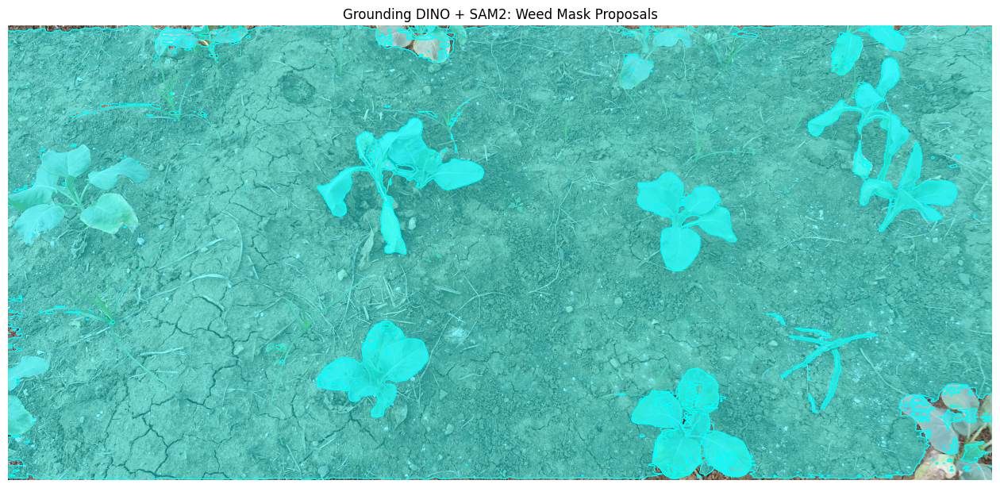

In [41]:
fig, ax = plt.subplots(figsize=(16, 9))

ax.imshow(image_rgb)

for i, mask in enumerate(weed_masks):

    mask = mask.astype(bool)

    overlay = np.zeros((*mask.shape, 4))
    overlay[mask] = [0, 1, 1, 0.45]

    ax.imshow(overlay)

    ax.contour(
        mask.astype(float),
        levels=[0.5],
        colors="cyan",
        linewidths=1
    )

ax.set_title("Grounding DINO + SAM2: Weed Mask Proposals")
ax.axis("off")

plt.show()